In [60]:
# Import the libraries needed for data analysis and visualization

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [61]:
# Read the Amazon UK CSV file
# Store the dataset in a DataFrame called df

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [62]:
# Display the first five rows
# This helps to inspect the columns and sample values

df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [63]:
#README says "rating", but the actual dataset uses the "stars" column

### Data Inspection


In [64]:
# Check the number of rows and columns
# Inspect the data types of each column
# Check whether any values are missing

print("Shape:", df.shape)

df.info()

print("\nMissing values:")
print(df.isna().sum())

Shape: (2443651, 9)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB

Missing values:
uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64


### Part 1: Understanding Product Categories

In [65]:
# Select the category column
# Count how many times each category appears
# Store the frequency table

category_frequency = df["category"].value_counts()

# Display the full frequency table
category_frequency

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

In [66]:
# Take the five categories with the highest listing counts

top_5_categories = category_frequency.head(5)

top_5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

#### Visualization of Top Product Categories

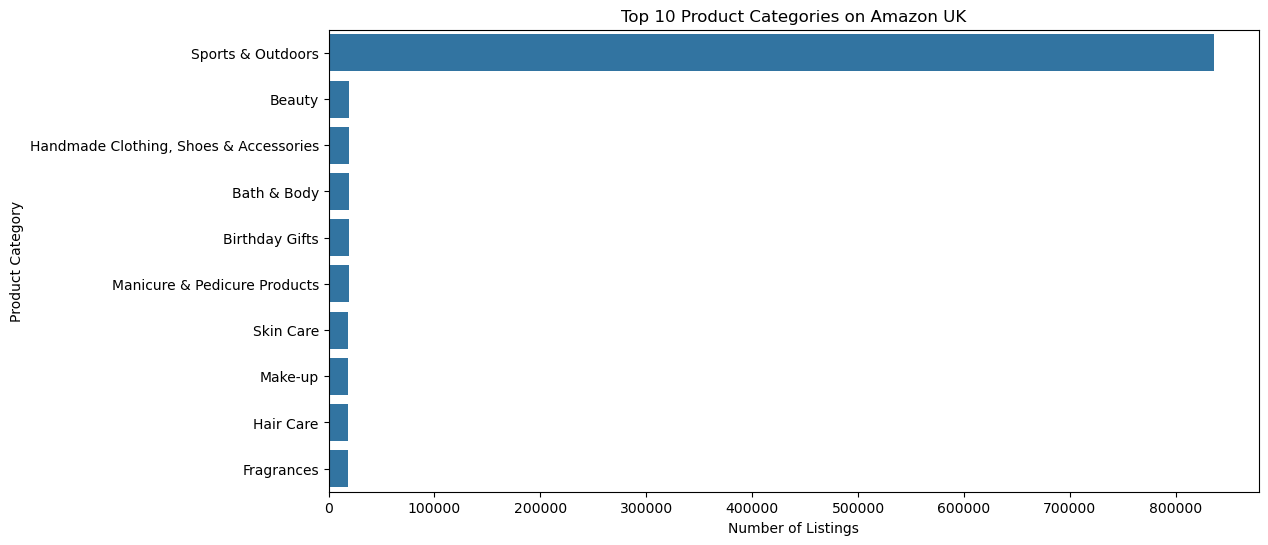

In [67]:
# Select the 10 categories with the highest number of listings

top_10_categories = category_frequency.head(10)

# Create a bar chart to compare their listing frequencies
plt.figure(figsize=(12, 6))

# Add a title and axis labels to make the chart easy to interpret

sns.barplot(
    x=top_10_categories.values,
    y=top_10_categories.index
)

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Number of Listings")
plt.ylabel("Product Category")

plt.show()

#### Proportion of Top 5 Product Categories

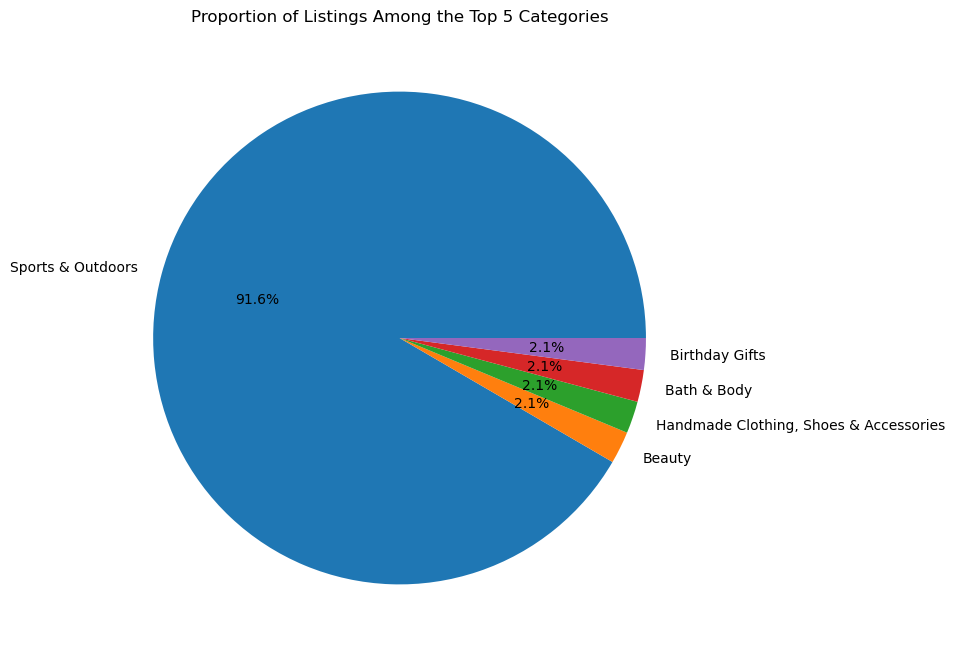

In [68]:
# Use the top 5 product categories
# Plot their listing counts as proportions in a pie chart
# Show percentage labels for easier comparison

plt.figure(figsize=(8, 8))

plt.pie(
    top_5_categories.values,
    labels=top_5_categories.index,
    autopct="%1.1f%%"
)

plt.title("Proportion of Listings Among the Top 5 Categories")

plt.show()

#### Interpretation

Sports & Outdoors is by far the most heavily represented category in the dataset. It has 836,265 listings, substantially more than the other leading categories, which each have around 19,000 listings. Among the top five categories, Sports & Outdoors accounts for roughly 91.6% of listings. This indicates a highly uneven category distribution, with Sports & Outdoors dominating the product listings.

### Part 2: Delving into Product Pricing

#### Measures of Centrality

In [69]:
# Select the price column
# Calculate the average price
# Calculate the middle price
# Find the most common price

price_mean = df["price"].mean()
price_median = df["price"].median()
price_mode = df["price"].mode()[0]

# Display the results
print("Mean price:", price_mean)
print("Median price:", price_median)
print("Mode price:", price_mode)

Mean price: 89.24380943923663
Median price: 19.09
Mode price: 9.99


#### Interpretation

The average product price is approximately £89.24, while the median price is £19.09 and the most common price is £9.99.

The mean is substantially higher than both the median and mode, suggesting that the price distribution is positively skewed. This likely indicates that most products are concentrated at lower price points, while a smaller number of very expensive products increase the overall average.

### Measures of Dispersion

Instruction requests for:
- variance
- standard deviation
- range
- interquartile range (IQR)

In [70]:
# Select the price column
# Calculate how spread out the prices are
# Find the variance and standard deviation
# Calculate the difference between maximum and minimum price
# Calculate Q1 and Q3
# Subtract Q1 from Q3 to obtain the IQR

price_variance = df["price"].var()
price_std = df["price"].std()

price_range = df["price"].max() - df["price"].min()

price_q1 = df["price"].quantile(0.25)
price_q3 = df["price"].quantile(0.75)
price_iqr = price_q3 - price_q1

# Display the results
print("Variance:", price_variance)
print("Standard deviation:", price_std)
print("Range:", price_range)
print("Q1:", price_q1)
print("Q3:", price_q3)
print("IQR:", price_iqr)

Variance: 119445.4853225653
Standard deviation: 345.6088617535223
Range: 100000.0
Q1: 9.99
Q3: 45.99
IQR: 36.0


#### Interpretation of Price Dispersion

The middle 50% of products are priced between £9.99 and £45.99, giving an interquartile range of £36.00.

However, the overall price range is £100,000 and the standard deviation is approximately £345.61. These values are very large compared with the IQR, suggesting that the dataset contains a relatively small number of extremely high-priced products.

This indicates substantial price dispersion and supports the earlier observation that the price distribution is strongly right-skewed.

### Visualizations

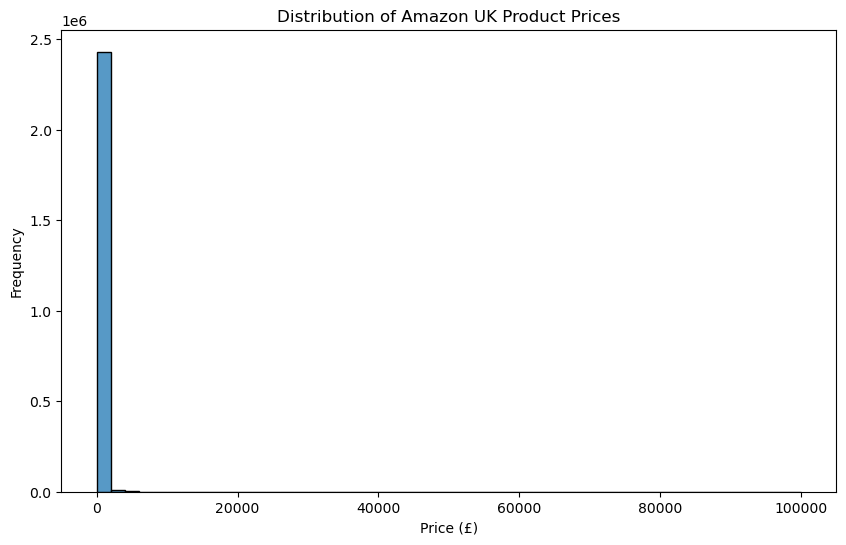

In [71]:
# Plot all product prices in a histogram
# Observe how the extremely high prices affect readability

plt.figure(figsize=(10, 6))

sns.histplot(
    data=df,
    x="price",
    bins=50
)

plt.title("Distribution of Amazon UK Product Prices")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")

plt.show()

### Note:

The full price histogram is difficult to interpret because a small number of extremely high-priced products stretch the x-axis. Most products are concentrated at much lower prices. To better visualize the main price distribution, the following histogram focuses on products priced at or below the 99th percentile.

In [72]:
# Find the price below which 99% of products fall
# Use this value only to make the histogram easier to read
# Do not remove the expensive products from the original dataset

price_99 = df["price"].quantile(0.99)

print("99th percentile:", price_99)

99th percentile: 1408.82


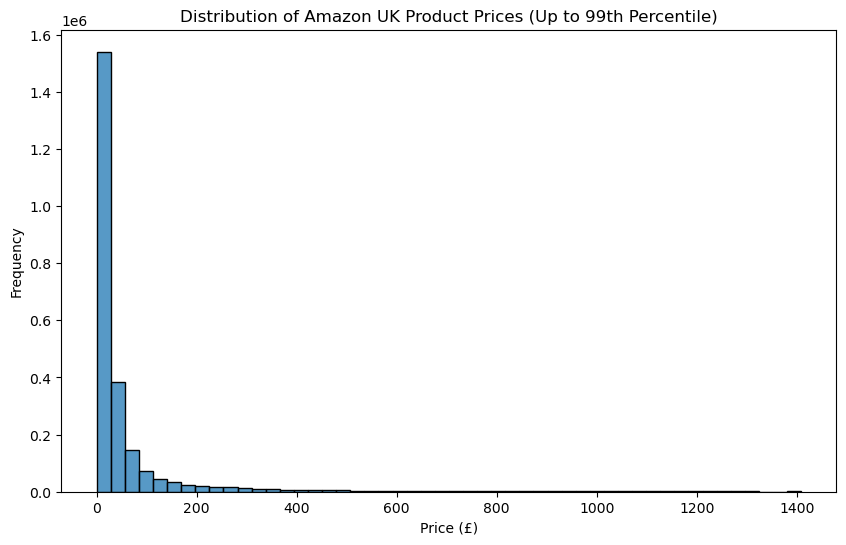

In [73]:
# Select prices up to the 99th percentile
# Plot a clearer histogram of the main price distribution

price_filtered = df[df["price"] <= price_99]

plt.figure(figsize=(10, 6))

sns.histplot(
    data=price_filtered,
    x="price",
    bins=50
)

plt.title("Distribution of Amazon UK Product Prices (Up to 99th Percentile)")
plt.xlabel("Price (£)")
plt.ylabel("Frequency")

plt.show()

#### Interpretation of the Price Distribution

The price distribution is strongly right-skewed. Most Amazon UK products are concentrated at relatively low price points, while the number of products decreases rapidly as price increases.

The long right tail indicates that a smaller number of products are substantially more expensive than the majority. This explains why the mean price (£89.24) is much higher than the median (£19.09) and mode (£9.99).

### Box plot

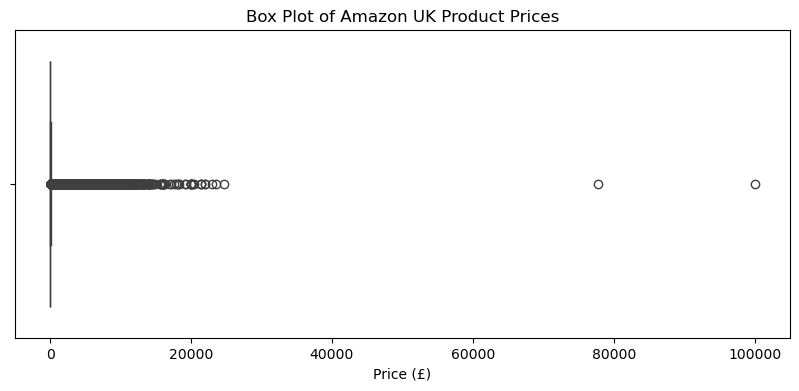

In [74]:
# Create a box plot of all product prices
# Use it to identify the typical price range
# and products that lie far above the rest

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=df,
    x="price"
)

plt.title("Box Plot of Amazon UK Product Prices")
plt.xlabel("Price (£)")

plt.show()

#### Interpretation of the Price Box Plot

The box plot shows a strongly right-skewed price distribution with many high-price outliers.

Most product prices are concentrated near the lower end of the scale, while a relatively small number of products have exceptionally high prices. These extreme values stretch the x-axis and make the central part of the box plot difficult to see clearly.

### Now create a zoomed box plot, using the same 99th-percentile subset we already created

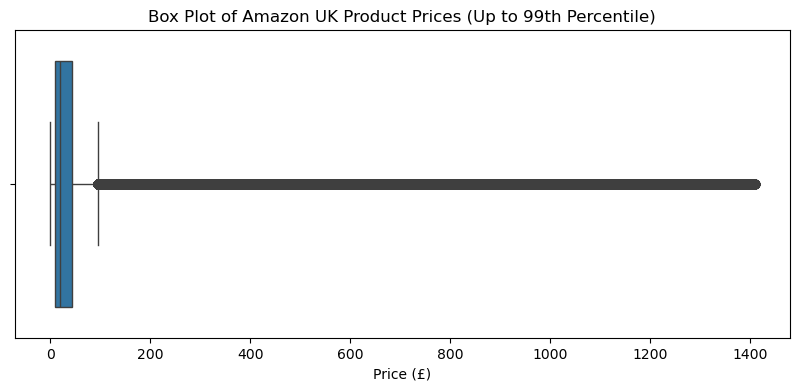

In [75]:
# Use products priced at or below the 99th percentile
# Create a second box plot
# This allows us to see the main price distribution more clearly

plt.figure(figsize=(10, 4))

sns.boxplot(
    data=price_filtered,
    x="price"
)

plt.title("Box Plot of Amazon UK Product Prices (Up to 99th Percentile)")
plt.xlabel("Price (£)")

plt.show()

### Quantifying the outliers using the standard 1.5 × IQR rule


In [76]:
# Calculate the lower and upper outlier boundaries
# using Q1, Q3, and the IQR

lower_bound = price_q1 - 1.5 * price_iqr
upper_bound = price_q3 + 1.5 * price_iqr

# Count products priced below the lower bound
# or above the upper bound

price_outliers = df[
    (df["price"] < lower_bound) |
    (df["price"] > upper_bound)
]

print("Lower bound:", lower_bound)
print("Upper bound:", upper_bound)
print("Number of price outliers:", len(price_outliers))

Lower bound: -44.01
Upper bound: 99.99000000000001
Number of price outliers: 327688


#### Interpretation of Price Outliers

Using the 1.5 × IQR rule, the upper outlier boundary is approximately £99.99.

A total of 327,688 products are identified as price outliers, representing about 13.4% of the dataset. Since the lower bound is negative, the relevant outliers are high-priced products.

This confirms that the price distribution has a substantial right tail, with many products priced well above the typical range.

### Part 3: Product Ratings

In [77]:
### Initial Inspection of Rating Values

In [78]:
# Select the stars column
# Calculate the mean rating
# Calculate the median rating
# Find the most common rating

rating_mean = df["stars"].mean()
rating_median = df["stars"].median()
rating_mode = df["stars"].mode()[0]

print("Mean rating:", rating_mean)
print("Median rating:", rating_median)
print("Mode rating:", rating_mode)

Mean rating: 2.152836472966065
Median rating: 0.0
Mode rating: 0.0


### Note

A 0.0 star rating is unusual on Amazon. It probably means the product has no rating yet, rather than customers actually rated it zero stars. So we should not yet conclude that customers generally rate products poorly.
Before continuing, check how many products have 0 stars and compare that with the reviews column

In [79]:
# PSEUDOCODE:
# Count how many products have each star rating
# Check how many products have zero stars
# Check whether zero-star products also have zero reviews

print(df["stars"].value_counts().sort_index())

zero_star_count = (df["stars"] == 0).sum()
zero_review_count = (df["reviews"] == 0).sum()

print("\nProducts with 0 stars:", zero_star_count)
print("Products with 0 reviews:", zero_review_count)

stars
0.0    1225641
1.0       8484
1.1          3
1.2         23
1.3         78
1.4        149
1.5        404
1.6        147
1.7        177
1.8        249
1.9        300
2.0       3901
2.1        540
2.2        602
2.3        734
2.4       1060
2.5       2103
2.6       1579
2.7       2104
2.8       2306
2.9       3341
3.0      12819
3.1       4679
3.2       5771
3.3       8269
3.4      10355
3.5      14673
3.6      16219
3.7      21137
3.8      27876
3.9      36555
4.0      66089
4.1      65115
4.2      86871
4.3     112564
4.4     136165
4.5     151577
4.6     136995
4.7      94566
4.8      41858
4.9      11081
5.0     128492
Name: count, dtype: int64

Products with 0 stars: 1225641
Products with 0 reviews: 1225641


In [80]:
# PSEUDOCODE:
# Look only at products with zero stars
# Check the review counts for those products

df[df["stars"] == 0]["reviews"].describe()

count    1225641.0
mean           0.0
std            0.0
min            0.0
25%            0.0
50%            0.0
75%            0.0
max            0.0
Name: reviews, dtype: float64

In [81]:
# Keep only products that actually have a star rating
rated_products = df[df["stars"] > 0]

In [82]:
rated_products["stars"]

0          4.7
1          4.7
2          4.7
3          4.7
4          4.6
          ... 
2443642    3.6
2443643    4.1
2443644    3.6
2443649    4.3
2443650    4.5
Name: stars, Length: 1218010, dtype: float64

#### Rating Data Preparation

The dataset contains 1,225,641 products with a star value of 0. These same products also have 0 reviews, indicating that a rating of 0 most likely represents products that have not yet been rated.

Therefore, the customer-rating analysis is performed only on products with `stars > 0`.

### Measures of Centrality

In [83]:
# Use only products that have an actual rating
# Calculate the average rating
# Calculate the middle rating
# Find the most common rating

rating_mean = rated_products["stars"].mean()
rating_median = rated_products["stars"].median()
rating_mode = rated_products["stars"].mode()[0]

print("Mean rating:", rating_mean)
print("Median rating:", rating_median)
print("Mode rating:", rating_mode)

Mean rating: 4.31916076222691
Median rating: 4.4
Mode rating: 4.5


#### Interpretation of Rating Centrality

Among products that have received ratings, the average rating is approximately 4.32 stars, the median is 4.4 stars, and the most common rating is 4.5 stars.

These values indicate that customer ratings are generally high, with ratings concentrated around the 4 to 5 star range. The mode of 4.5 suggests that this is a particularly common customer rating.

### Measures of Dispersion

In [84]:
# Use only products with actual ratings
# Calculate the variance and standard deviation
# Find the first and third quartiles
# Subtract Q1 from Q3 to calculate the IQR

rating_variance = rated_products["stars"].var()
rating_std = rated_products["stars"].std()

rating_q1 = rated_products["stars"].quantile(0.25)
rating_q3 = rated_products["stars"].quantile(0.75)
rating_iqr = rating_q3 - rating_q1

# Display the results
print("Variance:", rating_variance)
print("Standard deviation:", rating_std)
print("Q1:", rating_q1)
print("Q3:", rating_q3)
print("IQR:", rating_iqr)

Variance: 0.30834337523805183
Standard deviation: 0.5552867504614637
Q1: 4.1
Q3: 4.6
IQR: 0.5


#### Interpretation of Rating Dispersion

Customer ratings show relatively low variability.

The standard deviation is approximately 0.56 stars, meaning ratings typically deviate from the mean by a little over half a star.

The middle 50% of rated products fall between 4.1 and 4.6 stars, giving an interquartile range of only 0.5 stars. This indicates that customer ratings are fairly consistent and concentrated at the higher end of the rating scale.

### Shape of the Distribution

In [85]:
# Measure whether the rating distribution leans left or right
# Measure how heavy or peaked the tails of the distribution are

rating_skewness = rated_products["stars"].skew()
rating_kurtosis = rated_products["stars"].kurt()

print("Skewness:", rating_skewness)
print("Kurtosis:", rating_kurtosis)

Skewness: -2.3795681122127945
Kurtosis: 9.78193769066435


#### Interpretation of Rating Distribution Shape

The rating distribution has a skewness of approximately -2.38, indicating a strong negative (left) skew. Most rated products are concentrated at the higher end of the rating scale, while relatively few products have much lower ratings.

The kurtosis is approximately 9.78, which is substantially above 0. This indicates a highly peaked distribution with heavier tails than a normal distribution.

Overall, customer ratings are not normally distributed and are strongly concentrated toward high ratings.

### Rating histogram

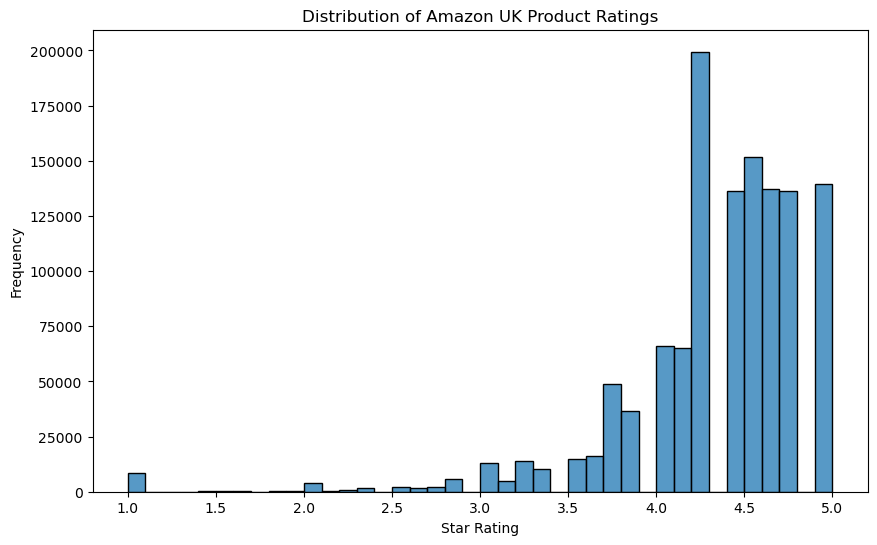

In [86]:
# Plot the distribution of actual product ratings
# Use only products with stars greater than 0
# Observe where most ratings are concentrated

plt.figure(figsize=(10, 6))

sns.histplot(
    data=rated_products,
    x="stars",
    bins=40
)

plt.title("Distribution of Amazon UK Product Ratings")
plt.xlabel("Star Rating")
plt.ylabel("Frequency")

plt.show()

#### Interpretation of Rating Histogram

The histogram shows that customer ratings are strongly concentrated at the higher end of the scale, particularly between 4 and 5 stars.

The exact mode is 4.5 stars, making it the most common individual rating in the dataset. Lower ratings occur much less frequently, creating a long tail toward the left.

This visual pattern supports the calculated skewness of approximately -2.38 and indicates that customers generally rate the listed products positively.

### Business Summary

The univariate analysis of Amazon UK product listings reveals several important patterns:

- **Product categories:** Sports & Outdoors dominates the dataset in terms of listing frequency, with substantially more products than the other leading categories. This indicates a highly uneven distribution of listings across categories.

- **Product pricing:** Product prices are strongly right-skewed. Although the average price is approximately £89.24, the median is only £19.09 and the most common price is £9.99. The middle 50% of products are priced between £9.99 and £45.99, while a substantial number of high-priced products create a long right tail.

- **Customer ratings:** After excluding unrated products, customer feedback is generally positive. The average rating is approximately 4.32 stars, the median is 4.4 stars, and the most common rating is 4.5 stars. Ratings are relatively consistent, with the middle 50% lying between 4.1 and 4.6 stars.

Overall, the dataset suggests that Amazon UK listings are heavily concentrated in certain product categories, most products occupy relatively low price ranges despite the presence of extreme high-price listings, and rated products generally receive favorable customer feedback.